# Notebook 01 — Leitura e análise exploratória

Lê o banco espectral, separa as colunas espectrais das de laboratório, descreve os atributos,
remove as amostras sem o atributo-alvo e salva os dados para o notebook 02.

**Entrada:** `dados/bssl.csv` (caminho em `config.py`) · **Saídas:** `resultados/dados_brutos.npz`, `resultados/df_limpo.pkl` e figuras `01_*.png`

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import config as cfg, utils

cfg.PASTA_FIG.mkdir(parents=True, exist_ok=True)

## 1. Leitura

In [2]:
df = pd.read_csv(cfg.ARQUIVO, encoding=cfg.ENCODING)
df = df.loc[:, ~df.columns.astype(str).str.match(r'^Unnamed')]
if cfg.MAX_AMOSTRAS and len(df) > cfg.MAX_AMOSTRAS:
    df = df.sample(cfg.MAX_AMOSTRAS, random_state=cfg.SEED).reset_index(drop=True)
    print(f'Amostra limitada a {cfg.MAX_AMOSTRAS} linhas (SEED={cfg.SEED})')
cols_esp, cols_ref = utils.identificar_colunas(df, cfg.PREFIXO)
wl_orig = utils.comprimentos_onda(cols_esp, cfg.PREFIXO)

print('Amostras:', df.shape[0])
print('Bandas espectrais:', len(cols_esp), f'({wl_orig.min():.0f} a {wl_orig.max():.0f} nm)')
print('Colunas de referência:', cols_ref)

Amostra limitada a 5000 linhas (SEED=42)
Amostras: 5000
Bandas espectrais: 2151 (350 a 2500 nm)
Colunas de referência: ['ID_Unico', 'Owner', 'X', 'Y', 'Country', 'Upper_depth_cm', 'Lower_depth_cm', 'Sand_gkg', 'Silt_gkg', 'Clay_gkg', 'Density_kgdm3', 'C_gkg', 'OM_gkg', 'P_mgkg', 'pH_H2O', 'Ca_mmolkg', 'Mg_mmolkg', 'K_mmolkg', 'CEC_Ph7_mmolkg', 'CEC_Efe_mmolkg', 'MacroN_g_kg']


## 2. Estatística descritiva e valores faltantes

In [3]:
display(df[cols_ref].describe().round(2))

faltantes = pd.DataFrame({'faltantes': df[cols_ref].isna().sum(),
                          '%': (100 * df[cols_ref].isna().mean()).round(1)})
display(faltantes)

,ID_Unico,X,Y,Upper_depth_cm,Lower_depth_cm,Sand_gkg,Silt_gkg,Clay_gkg,Density_kgdm3,C_gkg,OM_gkg,P_mgkg,pH_H2O,Ca_mmolkg,Mg_mmolkg,K_mmolkg,CEC_Ph7_mmolkg,CEC_Efe_mmolkg,MacroN_g_kg
count,5000.00,4998.00,4998.00,3545.00,3543.00,3524.00,3531.00,3610.00,226.00,3967.00,197.00,2763.00,3483.00,380.00,357.00,2921.00,476.00,2333.00,2681.00
mean,149776.61,22.24,34.73,9.52,30.43,408.97,346.04,206.75,1.12,43.28,21.68,29.78,6.31,123.61,30.25,5.01,130.51,153.29,3.09
std,89682.45,55.90,23.90,30.01,34.32,266.56,196.29,160.67,0.41,89.58,28.03,35.33,1.37,174.47,45.63,6.89,133.80,133.46,4.20
min,2.00,-172.36,-42.77,0.00,2.00,0.00,0.00,0.00,0.08,0.21,0.00,0.00,3.40,1.00,1.00,0.00,2.00,10.00,0.00
25%,61689.00,-2.41,28.38,0.00,20.00,170.00,200.00,80.00,0.90,9.50,10.00,5.70,5.10,12.00,5.00,1.66,32.92,69.00,1.10
50%,215614.00,15.17,41.03,0.00,20.00,390.00,340.00,180.00,1.19,16.80,15.00,20.10,6.32,55.00,16.00,3.15,90.50,124.00,1.70
75%,226410.75,32.65,50.02,0.00,20.00,620.00,480.00,290.00,1.42,32.70,22.76,40.95,7.57,173.25,38.00,6.00,178.25,200.00,2.90
max,238976.00,155.41,68.92,420.00,450.00,991.90,951.90,944.00,1.86,591.11,182.11,575.10,10.58,1256.36,527.00,175.47,937.00,2045.00,34.20


,faltantes,%
ID_Unico,0,0.0
Owner,0,0.0
X,2,0.0
Y,2,0.0
Country,413,8.3
Upper_depth_cm,1455,29.1
Lower_depth_cm,1457,29.1
Sand_gkg,1476,29.5
Silt_gkg,1469,29.4
Clay_gkg,1390,27.8


## 3. Limpeza

Remove as amostras sem o atributo-alvo e as com bandas faltantes. `X` e `y` são definidos
**depois** da limpeza, com as linhas na mesma ordem de `df`.

In [4]:
n_antes = len(df)
df = df.dropna(subset=[cfg.COL_ALVO])
df = df[df[cols_esp].notna().all(axis=1)].reset_index(drop=True)
print(f'Amostras: {n_antes} -> {len(df)} após a limpeza')
print(f'Assimetria de {cfg.COL_ALVO}: {df[cfg.COL_ALVO].skew():.2f}')

X = df[cols_esp].to_numpy(dtype=float)       # reflectância bruta
y = df[cfg.COL_ALVO].to_numpy(dtype=float)
print('X:', X.shape, '| y:', y.shape)

Amostras: 5000 -> 1150 após a limpeza
Assimetria de Clay_gkg: 0.86
X: (1150, 2151) | y: (1150,)


## 4. Distribuição do atributo-alvo

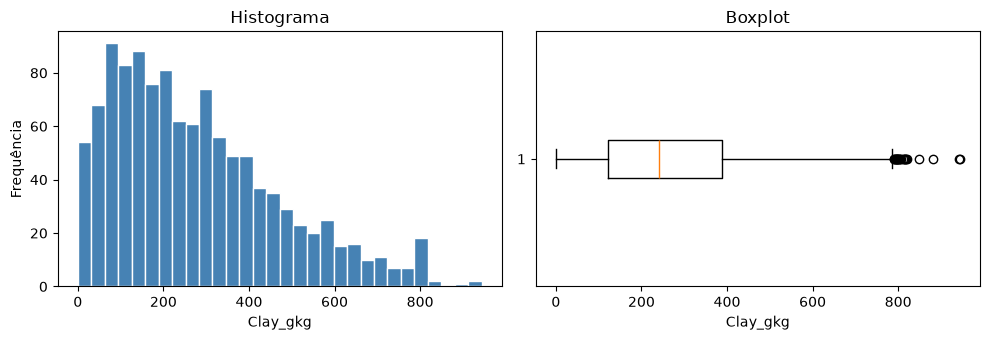

In [5]:
y = df[cfg.COL_ALVO].dropna().to_numpy(dtype=float)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(y, bins=30, color='steelblue', edgecolor='white')
ax[0].set_xlabel(cfg.COL_ALVO); ax[0].set_ylabel('Frequência'); ax[0].set_title('Histograma')
ax[1].boxplot(y, vert=False)
ax[1].set_xlabel(cfg.COL_ALVO); ax[1].set_title('Boxplot')
plt.tight_layout(); utils.salva_figura(fig, '01_distribuicao_alvo.png'); plt.show()

## 5. Espectros brutos

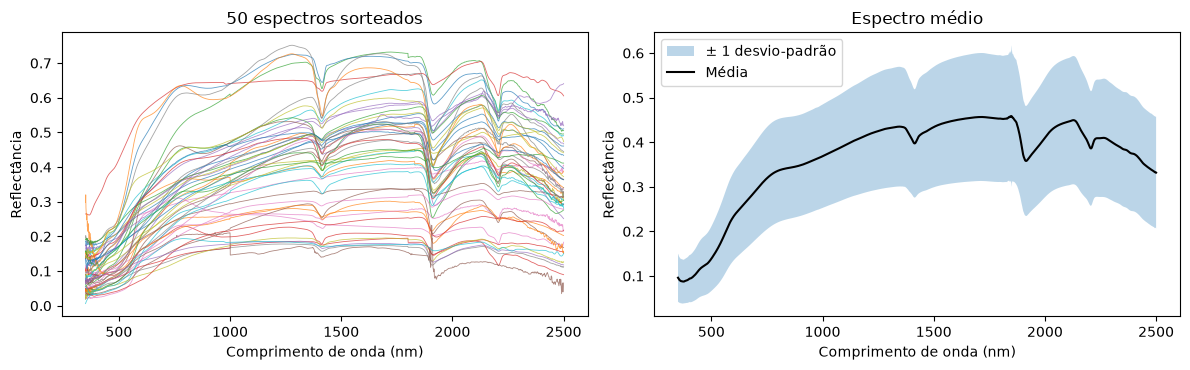

In [6]:
rng = np.random.default_rng(cfg.SEED)
amostra = rng.choice(len(X), min(50, len(X)), replace=False)
media, dp = X.mean(axis=0), X.std(axis=0)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(wl_orig, X[amostra].T, lw=0.6, alpha=0.7)
ax[0].set_title('50 espectros sorteados')
ax[1].fill_between(wl_orig, media - dp, media + dp, alpha=0.3, label='± 1 desvio-padrão')
ax[1].plot(wl_orig, media, color='black', label='Média')
ax[1].set_title('Espectro médio'); ax[1].legend()
for a in ax:
    a.set_xlabel('Comprimento de onda (nm)'); a.set_ylabel('Reflectância')
plt.tight_layout(); utils.salva_figura(fig, '01_espectros_brutos.png'); plt.show()

## 6. Correlação de cada banda com o atributo-alvo

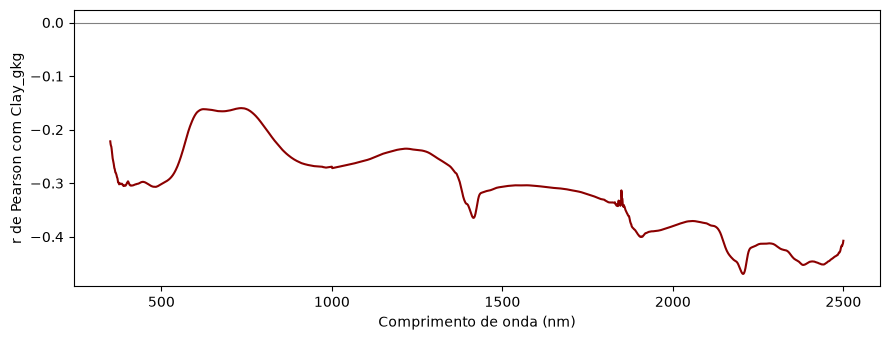

Maior |r|: 0.47 em 2206 nm


In [7]:
Xc = X - X.mean(axis=0)
yc = y - y.mean()
corr = (Xc * yc[:, None]).sum(axis=0) / (np.sqrt((Xc ** 2).sum(axis=0)) * np.sqrt((yc ** 2).sum()))

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(wl_orig, corr, color='darkred')
ax.axhline(0, color='gray', lw=0.8)
ax.set_xlabel('Comprimento de onda (nm)'); ax.set_ylabel(f'r de Pearson com {cfg.COL_ALVO}')
plt.tight_layout(); utils.salva_figura(fig, '01_correlacao_bandas.png'); plt.show()
print(f'Maior |r|: {np.abs(corr).max():.2f} em {wl_orig[np.abs(corr).argmax()]:.0f} nm')

## 7. Salvar

In [8]:
cfg.PASTA.mkdir(parents=True, exist_ok=True)
np.savez(cfg.PASTA / 'dados_brutos.npz', X=X, y=y, wl_orig=wl_orig)
df.to_pickle(cfg.PASTA / 'df_limpo.pkl')
print('Salvos: dados_brutos.npz e df_limpo.pkl em', cfg.PASTA)

Salvos: dados_brutos.npz e df_limpo.pkl em resultados
